# Lab 8 : Multiple Linear Regression
**Lakshay** : AP24110010677 : B.Tech CSE (AI/ML)

**Question** : Marks of 6 students depend on **two** factors : hours studied ($x_1$) and hours slept ($x_2$). Fit a **multiple linear regression** model, predict the marks of a student who studies 5 hours and sleeps 7 hours, and evaluate the model.

Solved **two ways** : (1) calculation with the matrix formula $\beta = (X^TX)^{-1}X^Ty$, step by step; (2) a program (scikit-learn).

## What is Multiple Linear Regression?
It is linear regression with **more than one** independent variable. For $p$ predictors:

$$y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_p x_p + \epsilon$$

* Each $\beta_j$ is the change in $y$ when $x_j$ goes up by 1, **keeping the other variables fixed**.
* Instead of a line, the model is a **plane** (2 predictors) or a hyper-plane (more).

**Matrix form** : for $n$ samples, $\;y = X\beta + \epsilon$, where $X$ is the $n \times (p+1)$ **design matrix** (first column all 1s for $\beta_0$).

Minimising $SSE = (y - X\beta)^T(y - X\beta)$ and setting the derivative to zero gives $X^TX\beta = X^Ty$, so

$$\boxed{\beta = (X^TX)^{-1}X^Ty}$$

**Assumptions** : linearity, homoscedasticity (equal error variance), uncorrelated errors, normally distributed errors, and no multicollinearity (predictors not strongly correlated with each other).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

np.random.seed(77)            # last two digits of roll number

## Dataset

In [2]:
df = pd.DataFrame({"study_hours": [2, 3, 4, 5, 6, 7],
                   "sleep_hours": [6, 5, 7, 8, 6, 8],
                   "marks":       [50, 55, 65, 72, 72, 85]})
y = df["marks"].values
n = len(y)
df

,study_hours,sleep_hours,marks
0,2,6,50
1,3,5,55
2,4,7,65
3,5,8,72
4,6,6,72
5,7,8,85


---
## Part 1 : Calculation (normal equation, step by step)
### Step 1 : build $X$ (column of 1s + predictors) and $y$

In [3]:
X = np.column_stack([np.ones(n), df["study_hours"], df["sleep_hours"]])
print("X =\n", X)
print("\ny =", y)
print("\nShape of X :", X.shape, " →  n × (p+1) = 6 × 3")

X =
 [[1. 2. 6.]
 [1. 3. 5.]
 [1. 4. 7.]
 [1. 5. 8.]
 [1. 6. 6.]
 [1. 7. 8.]]

y = [50 55 65 72 72 85]

Shape of X : (6, 3)  →  n × (p+1) = 6 × 3


### Step 2 : $X^TX$

In [4]:
XtX = X.T @ X
print("XᵀX =\n", XtX)

XᵀX =
 [[  6.  27.  40.]
 [ 27. 139. 187.]
 [ 40. 187. 274.]]


### Step 3 : $(X^TX)^{-1}$
For a 3×3 matrix this is $\frac{1}{|X^TX|}\,\text{adj}(X^TX)$.

In [5]:
det = np.linalg.det(XtX)
XtX_inv = np.linalg.inv(XtX)
print(f"|XᵀX| = {det:.2f}")
print("\n(XᵀX)⁻¹ =\n", XtX_inv.round(4))

|XᵀX| = 476.00

(XᵀX)⁻¹ =
 [[ 6.5483  0.1723 -1.0735]
 [ 0.1723  0.0924 -0.0882]
 [-1.0735 -0.0882  0.2206]]


### Step 4 : $X^Ty$

In [6]:
Xty = X.T @ y
print("Xᵀy =", Xty)

Xᵀy = [ 399. 1912. 2718.]


### Step 5 : $\beta = (X^TX)^{-1}X^Ty$

In [7]:
beta = XtX_inv @ Xty
b0, b1, b2 = beta
print(f"β₀ = {b0:.4f}\nβ₁ = {b1:.4f}  (study hours)\nβ₂ = {b2:.4f}  (sleep hours)")
print(f"\nModel :  ŷ = {b0:.4f} + {b1:.4f}·x₁ + {b2:.4f}·x₂")

β₀ = 24.3046
β₁ = 5.6513  (study hours)
β₂ = 2.5147  (sleep hours)

Model :  ŷ = 24.3046 + 5.6513·x₁ + 2.5147·x₂


### Step 6 : prediction (study = 5 h, sleep = 7 h)

In [8]:
print(f"ŷ = {b0:.4f} + {b1:.4f}×5 + {b2:.4f}×7 = {b0 + b1*5 + b2*7:.2f} marks")

ŷ = 24.3046 + 5.6513×5 + 2.5147×7 = 70.16 marks


---
## Part 2 : Program (scikit-learn)

In [9]:
features = df[["study_hours", "sleep_hours"]]
model = LinearRegression()
model.fit(features, y)

print(f"β₀ (sklearn) = {model.intercept_:.4f}   |   by hand = {b0:.4f}")
print(f"β₁ (sklearn) = {model.coef_[0]:.4f}   |   by hand = {b1:.4f}")
print(f"β₂ (sklearn) = {model.coef_[1]:.4f}   |   by hand = {b2:.4f}")
new = pd.DataFrame({"study_hours": [5], "sleep_hours": [7]})
print(f"Prediction (5 h study, 7 h sleep) = {model.predict(new)[0]:.2f}")

β₀ (sklearn) = 24.3046   |   by hand = 24.3046
β₁ (sklearn) = 5.6513   |   by hand = 5.6513
β₂ (sklearn) = 2.5147   |   by hand = 2.5147
Prediction (5 h study, 7 h sleep) = 70.16


---
## Evaluation
### Theory : how good is the model?
* **R² (coefficient of determination)** : what fraction of the variation in $y$ the model explains. Closer to **1** is better.
$$R^2 = 1 - \frac{SSE}{SST} = \frac{SSR}{SST}, \quad SSE=\sum(y_i-\hat y_i)^2,\; SST=\sum(y_i-\bar y)^2,\; SSR=\sum(\hat y_i-\bar y)^2$$
* **RMSE** : $\sqrt{\frac{1}{n}\sum(y_i-\hat y_i)^2}$ : average size of the error, in the same unit as $y$. Lower is better.
* **MAE** : $\frac{1}{n}\sum|y_i-\hat y_i|$ : average absolute error. Lower is better.

In [10]:
y_hat = model.predict(features)
y_bar = y.mean()

ev = df.copy()
ev["ŷ"] = y_hat.round(3)
ev["e = y - ŷ"] = (y - y_hat).round(3)
print(ev.to_string(index=False))

SSE = ((y - y_hat) ** 2).sum()
SST = ((y - y_bar) ** 2).sum()
print(f"\nCalculation :  SSE = {SSE:.4f},  SST = {SST:.4f}")
print(f"R² = 1 - SSE/SST = {1 - SSE/SST:.4f},  RMSE = {np.sqrt(SSE/n):.4f},  MAE = {np.abs(y-y_hat).mean():.4f}")
print(f"\nsklearn     :  R² = {r2_score(y, y_hat):.4f},  RMSE = {np.sqrt(mean_squared_error(y, y_hat)):.4f},  MAE = {mean_absolute_error(y, y_hat):.4f}")

 study_hours  sleep_hours  marks      ŷ  e = y - ŷ
           2            6     50 50.695     -0.695
           3            5     55 53.832      1.168
           4            7     65 64.513      0.487
           5            8     72 72.679     -0.679
           6            6     72 73.300     -1.300
           7            8     85 83.981      1.019

Calculation :  SSE = 5.2752,  SST = 809.5000
R² = 1 - SSE/SST = 0.9935,  RMSE = 0.9377,  MAE = 0.8915

sklearn     :  R² = 0.9935,  RMSE = 0.9377,  MAE = 0.8915


### Simple vs Multiple : does adding sleep hours help?

In [11]:
simple = LinearRegression().fit(df[["study_hours"]], y)
r2_simple = r2_score(y, simple.predict(df[["study_hours"]]))
print(f"R² with study hours only        = {r2_simple:.4f}")
print(f"R² with study + sleep hours     = {r2_score(y, y_hat):.4f}")

R² with study hours only        = 0.9581
R² with study + sleep hours     = 0.9935


### Plot : actual vs predicted
Points close to the diagonal line mean good predictions.

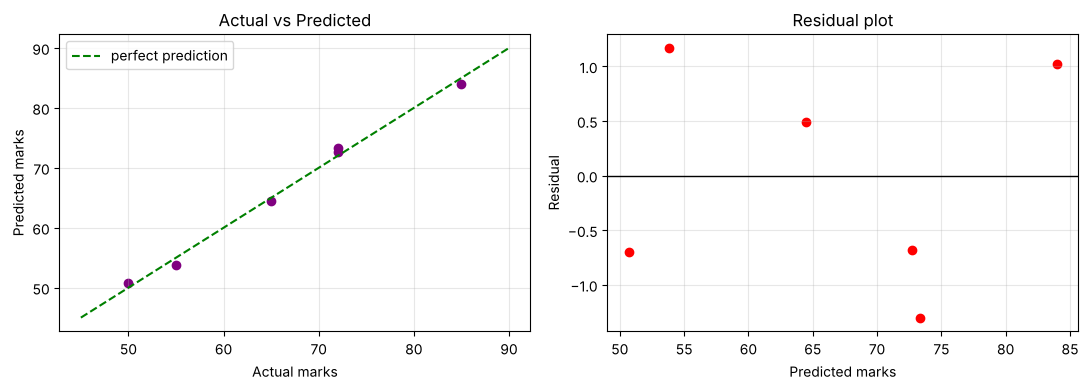

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].scatter(y, y_hat, color="purple")
ax[0].plot([45, 90], [45, 90], "g--", label="perfect prediction")
ax[0].set_xlabel("Actual marks"); ax[0].set_ylabel("Predicted marks")
ax[0].set_title("Actual vs Predicted"); ax[0].legend(); ax[0].grid(alpha=0.3)

ax[1].scatter(y_hat, y - y_hat, color="red")
ax[1].axhline(0, color="black", lw=1)
ax[1].set_xlabel("Predicted marks"); ax[1].set_ylabel("Residual")
ax[1].set_title("Residual plot"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Conclusion
* The matrix calculation $\beta=(X^TX)^{-1}X^Ty$ and scikit-learn give the **same** coefficients.
* Holding sleep constant, each extra hour of study adds about **5.65 marks**; holding study constant, each extra hour of sleep adds about **2.51 marks**. A student who studies 5 h and sleeps 7 h is predicted to score **70.16**.
* The model explains about **99 %** of the variation in marks (R² ≈ 0.994), higher than using study hours alone (R² ≈ 0.958), so the second variable adds useful information.